<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Scatter Plot**


Estimated time needed: **45** minutes


## Overview

In this lab, you will focus on creating and interpreting scatter plots to visualize relationships between variables and trends in the dataset. The provided dataset will be directly loaded into a pandas DataFrame, and various scatter plot-related visualizations will be created to explore developer trends, compensation, and preferences.



## Objectives


In this lab, you will:

- Create and analyze scatter plots to examine relationships between variables.

- Use scatter plots to identify trends and patterns in the dataset.

- Focus on visualizations centered on scatter plots for better data-driven insights.


## Setup: Working with the Database



**Install and import the required libraries**


In [1]:
!pip install pandas 
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 130.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 176.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 93.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 127.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 110.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


#### Step 1: Load the dataset


In [2]:
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

df = pd.read_csv(file_path)



### Task 1: Exploring Relationships with Scatter Plots



#### 1. Scatter Plot for Age vs. Job Satisfaction



Visualize the relationship between respondents' age (`Age`) and job satisfaction (`JobSatPoints_6`). Use this plot to identify any patterns or trends.




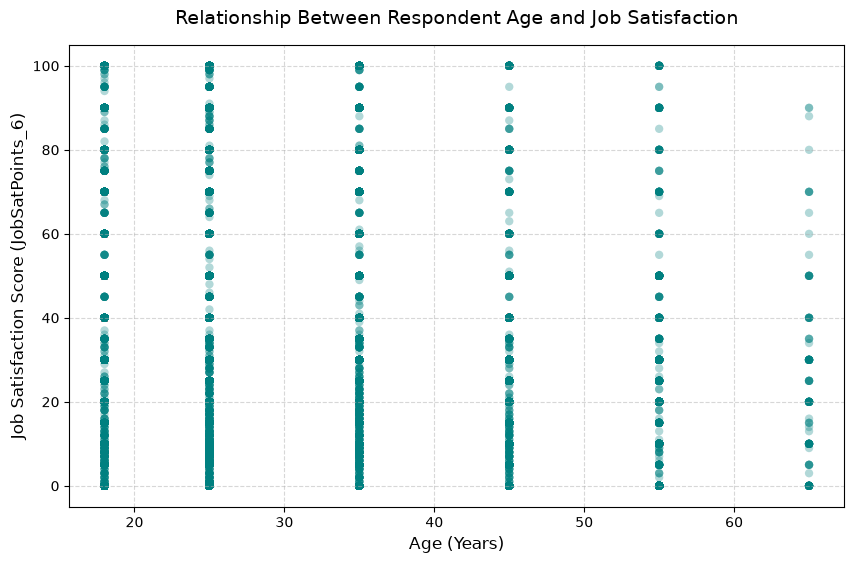

In [5]:
# Extract numbers out of the Age column if formatted as strings, and convert to numeric
df['Age'] = pd.to_numeric(df['Age'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop missing values across our target axes
df_clean = df.dropna(subset=['Age', 'JobSatPoints_6'])

plt.figure(figsize=(10, 6))

# Generate the scatter plot
plt.scatter(
    x=df_clean['Age'], 
    y=df_clean['JobSatPoints_6'], 
    alpha=0.3, 
    color='teal', 
    edgecolors='none'
)

# Label formatting and titles
plt.title('Relationship Between Respondent Age and Job Satisfaction', fontsize=14, pad=15)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Job Satisfaction Score (JobSatPoints_6)', fontsize=12)

# Set grid lines to better trace point patterns
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()


#### 2. Scatter Plot for Compensation vs. Job Satisfaction


Explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) using a scatter plot.


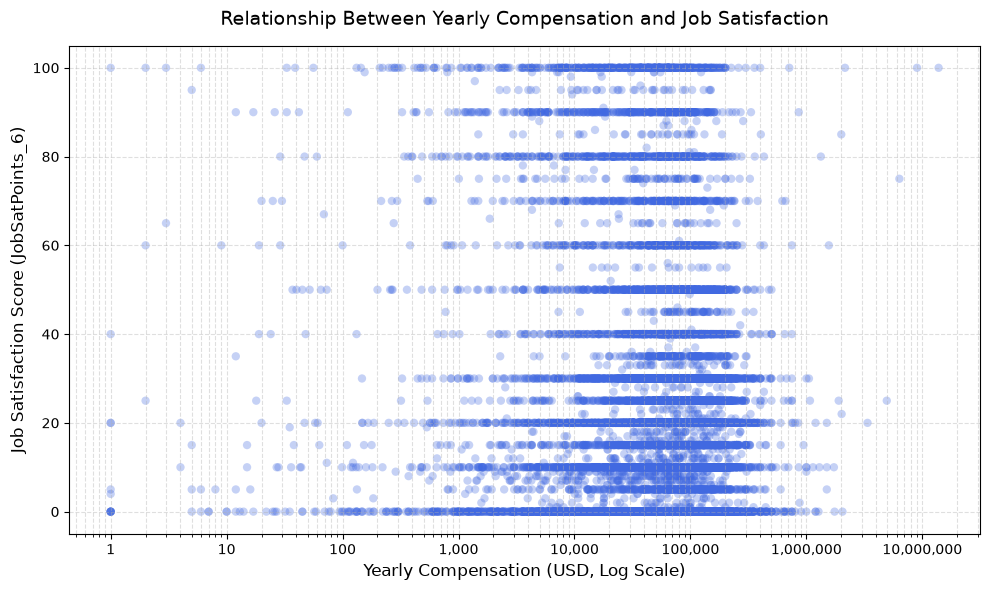

In [6]:
import matplotlib.ticker as ticker

# Enforce numeric types for accurate distribution math
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop rows missing either target variable
df_comp_sat = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6'])

plt.figure(figsize=(10, 6))

# Generate the scatter plot
plt.scatter(
    x=df_comp_sat['ConvertedCompYearly'], 
    y=df_comp_sat['JobSatPoints_6'], 
    alpha=0.3, 
    color='royalblue', 
    edgecolors='none'
)

# Apply a log scale to spread out the compensation distribution fairly
plt.xscale('log')

# Format the x-axis numbers to show standard commas instead of scientific notation
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# Titles and axis formatting
plt.title('Relationship Between Yearly Compensation and Job Satisfaction', fontsize=14, pad=15)
plt.xlabel('Yearly Compensation (USD, Log Scale)', fontsize=12)
plt.ylabel('Job Satisfaction Score (JobSatPoints_6)', fontsize=12)

plt.grid(True, which="both", linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### Task 2: Enhancing Scatter Plots


#### 1. Scatter Plot with Trend Line for Age vs. Job Satisfaction



Add a regression line to the scatter plot of Age vs. JobSatPoints_6 to highlight trends in the data.


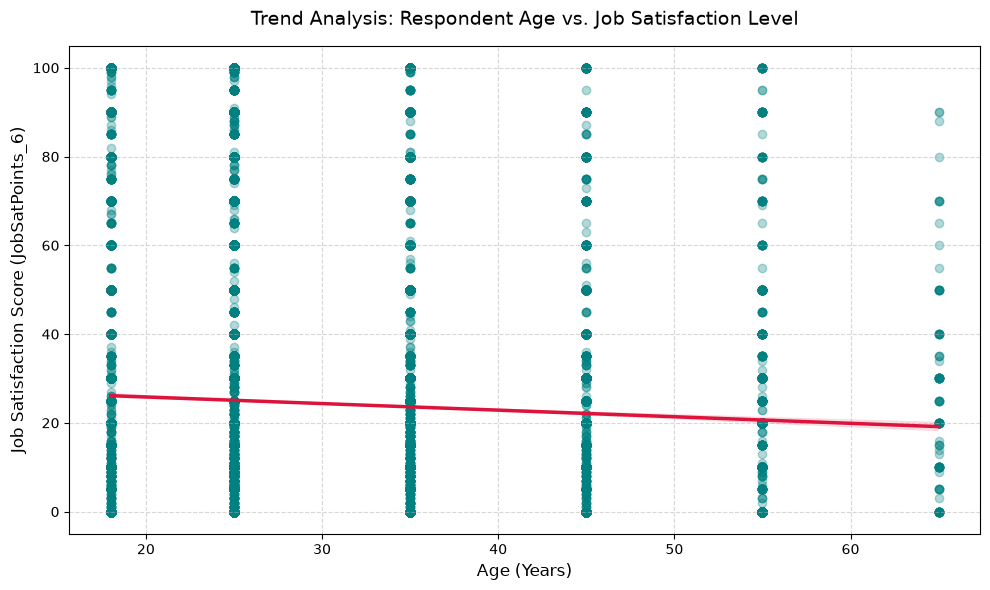

In [7]:
# Extract integers from the Age column and enforce numeric structures
df['Age'] = pd.to_numeric(df['Age'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop missing values to prepare a clean data slice for regression
df_clean = df.dropna(subset=['Age', 'JobSatPoints_6'])

plt.figure(figsize=(10, 6))

# Generate scatter points coupled with a linear regression line
sns.regplot(
    data=df_clean, 
    x='Age', 
    y='JobSatPoints_6', 
    scatter_kws={'alpha': 0.3, 'color': 'teal'}, 
    line_kws={'color': 'crimson', 'linewidth': 2.5}
)

# Graphic titles and formatting
plt.title('Trend Analysis: Respondent Age vs. Job Satisfaction Level', fontsize=14, pad=15)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Job Satisfaction Score (JobSatPoints_6)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### 2. Scatter Plot for Age vs. Work Experience


Visualize the relationship between Age (`Age`) and Work Experience (`YearsCodePro`) using a scatter plot.


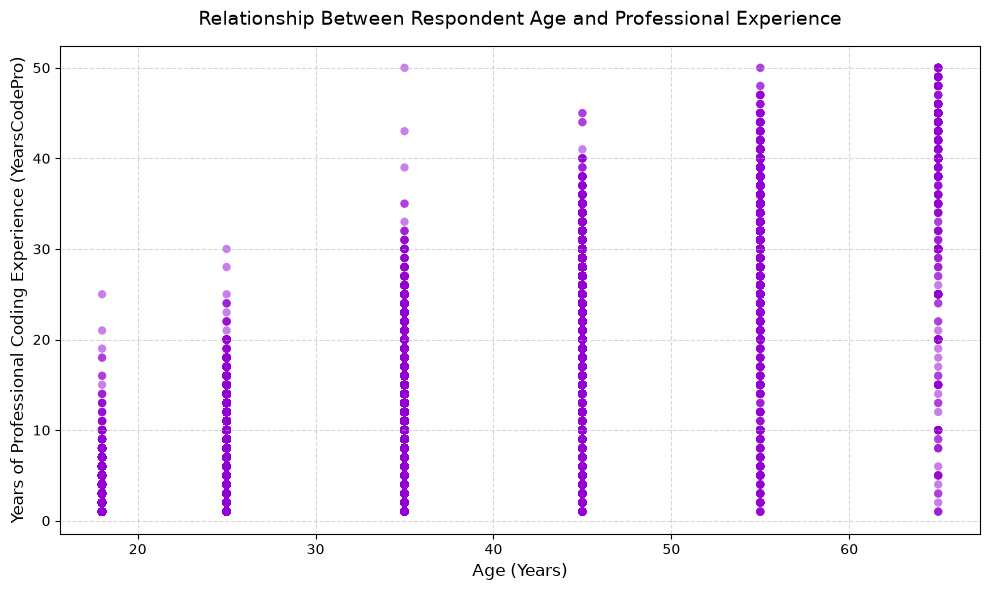

In [8]:
# Extract numeric digits and convert columns to clean numeric profiles
df['Age'] = pd.to_numeric(df['Age'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce')

# Drop empty entries across both target axes
df_exp = df.dropna(subset=['Age', 'YearsCodePro'])

plt.figure(figsize=(10, 6))

# Plot the scatter points using semi-transparency to handle overlapping coordinates
plt.scatter(
    x=df_exp['Age'], 
    y=df_exp['YearsCodePro'], 
    alpha=0.5, 
    color='darkviolet', 
    edgecolors='none'
)

# Structural labels and design styling
plt.title('Relationship Between Respondent Age and Professional Experience', fontsize=14, pad=15)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Years of Professional Coding Experience (YearsCodePro)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Task 3: Combining Scatter Plots with Additional Features


#### 1. Bubble Plot of Compensation vs. Job Satisfaction with Age as Bubble Size



Create a bubble plot to explore the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), with bubble size representing age.


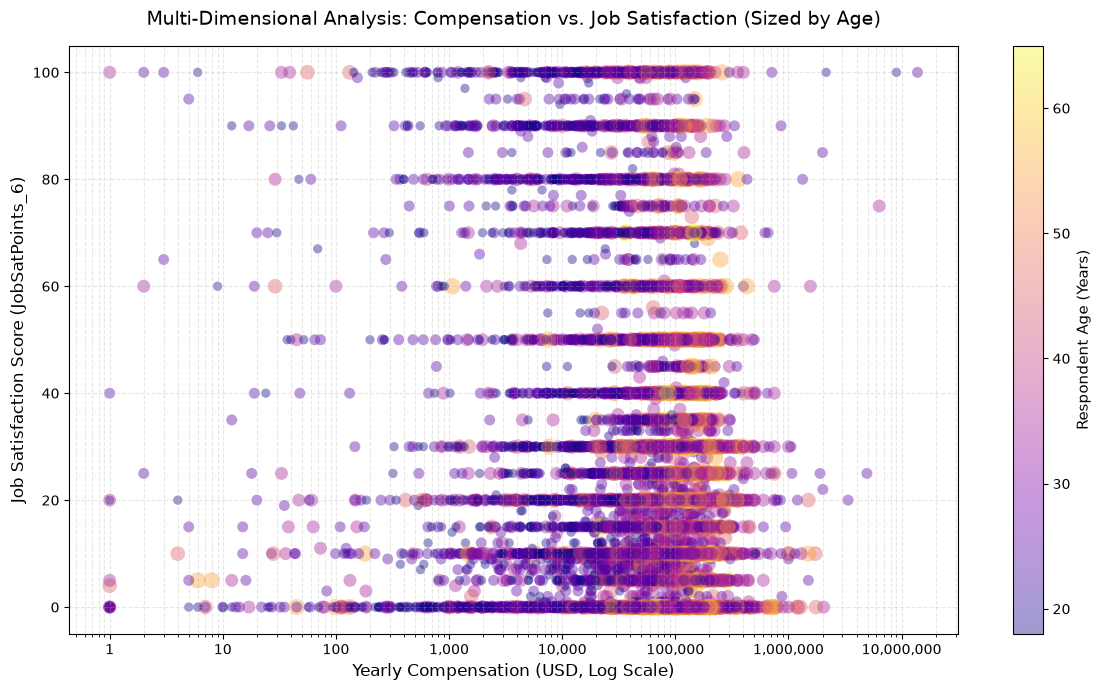

In [9]:
# Enforce clean numeric data structures
df['Age'] = pd.to_numeric(df['Age'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Isolate columns and remove missing rows
df_bubble = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6', 'Age'])

plt.figure(figsize=(12, 7))

# Generate the bubble plot mapping 's' to Age footprint and 'c' to Age color gradient
scatter = plt.scatter(
    x=df_bubble['ConvertedCompYearly'],
    y=df_bubble['JobSatPoints_6'],
    s=df_bubble['Age'] * 2.5,        # Adjust multiplier if bubbles appear too large/small
    c=df_bubble['Age'],              # Colors the bubbles according to age scale
    cmap='plasma',                   # Clean, high-contrast visual gradient
    alpha=0.4,                       # Transparency allows visibility of stacked data
    edgecolors='none'
)

# Apply a log scale to handle high-earning salary outliers smoothly
plt.xscale('log')

# Format x-axis integers with commas instead of scientific notation strings
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# Text alignments and labels
plt.title('Multi-Dimensional Analysis: Compensation vs. Job Satisfaction (Sized by Age)', fontsize=14, pad=15)
plt.xlabel('Yearly Compensation (USD, Log Scale)', fontsize=12)
plt.ylabel('Job Satisfaction Score (JobSatPoints_6)', fontsize=12)

# Embed a colorbar to act as a visual legend for the age gradient
cbar = plt.colorbar(scatter)
cbar.set_label('Respondent Age (Years)', fontsize=11)

plt.grid(True, which="both", linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


#### 2. Scatter Plot for Popular Programming Languages by Job Satisfaction


Visualize the popularity of programming languages (`LanguageHaveWorkedWith`) against job satisfaction using a scatter plot. Use points to represent satisfaction levels for each language.


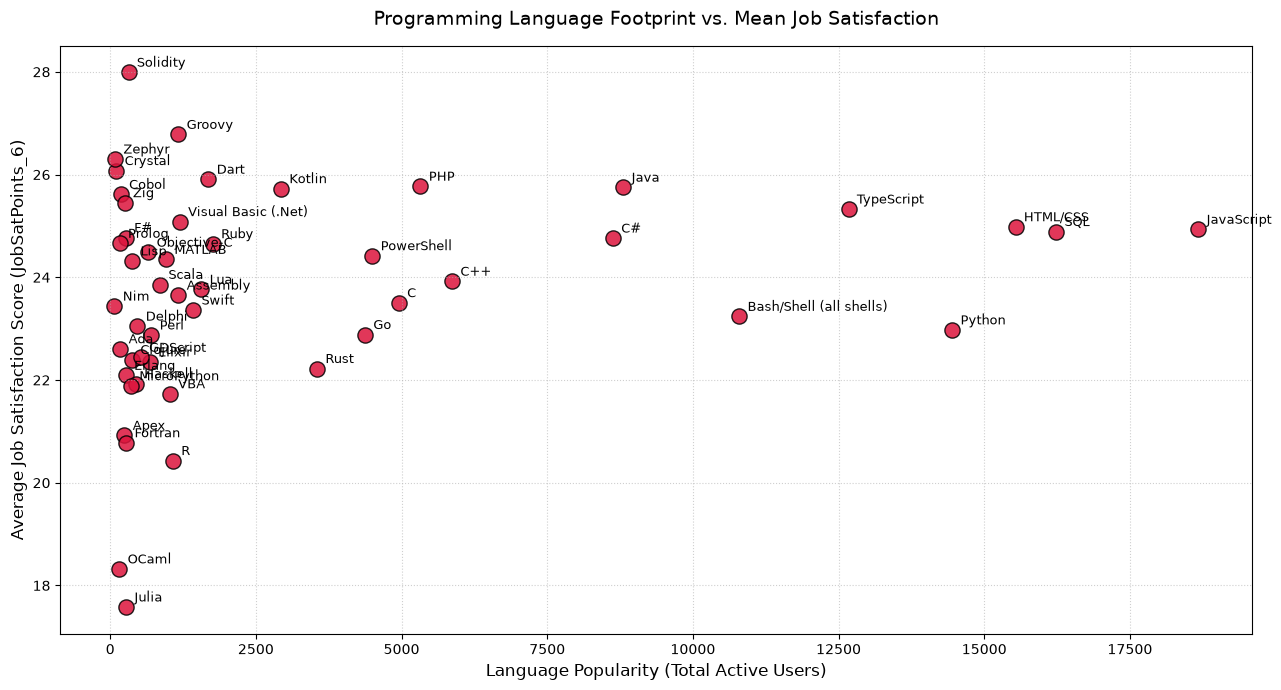

In [10]:
# Enforce clean numeric types for job satisfaction mapping
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop missing values across our target evaluation columns
df_lang = df.dropna(subset=['LanguageHaveWorkedWith', 'JobSatPoints_6']).copy()

# 1. Split the semi-colon strings into Python lists
df_lang['LanguageHaveWorkedWith'] = df_lang['LanguageHaveWorkedWith'].str.split(';')

# 2. Explode the lists so each unique language gets its own row matching its satisfaction score
df_exploded = df_lang.explode('LanguageHaveWorkedWith')

# 3. Group by language to isolate total user footprints and average contentment scores
lang_stats = df_exploded.groupby('LanguageHaveWorkedWith').agg(
    Popularity=('JobSatPoints_6', 'count'),
    Avg_Satisfaction=('JobSatPoints_6', 'mean')
).reset_index()

plt.figure(figsize=(13, 7))

# Generate the scatter plot
plt.scatter(
    x=lang_stats['Popularity'], 
    y=lang_stats['Avg_Satisfaction'], 
    color='crimson', 
    s=120,                # Noticeable point size
    edgecolors='black', 
    alpha=0.85
)

# Overlay text annotations for each point on the canvas
for idx, row in lang_stats.iterrows():
    plt.annotate(
        row['LanguageHaveWorkedWith'], 
        (row['Popularity'], row['Avg_Satisfaction']),
        textcoords="offset points", 
        xytext=(6, 4),      # Small visual offset so text does not overlap the dot center
        ha='left', 
        fontsize=9
    )

# Visual layout adjustments
plt.title('Programming Language Footprint vs. Mean Job Satisfaction', fontsize=14, pad=15)
plt.xlabel('Language Popularity (Total Active Users)', fontsize=12)
plt.ylabel('Average Job Satisfaction Score (JobSatPoints_6)', fontsize=12)

plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


### Task 4: Scatter Plot Comparisons Across Groups


#### 1. Scatter Plot for Compensation vs. Job Satisfaction by Employment Type


Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`), categorized by employment type (`Employment`). Use color coding or markers to differentiate between employment types.


/tmp/ipykernel_301/1302733322.py:36: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

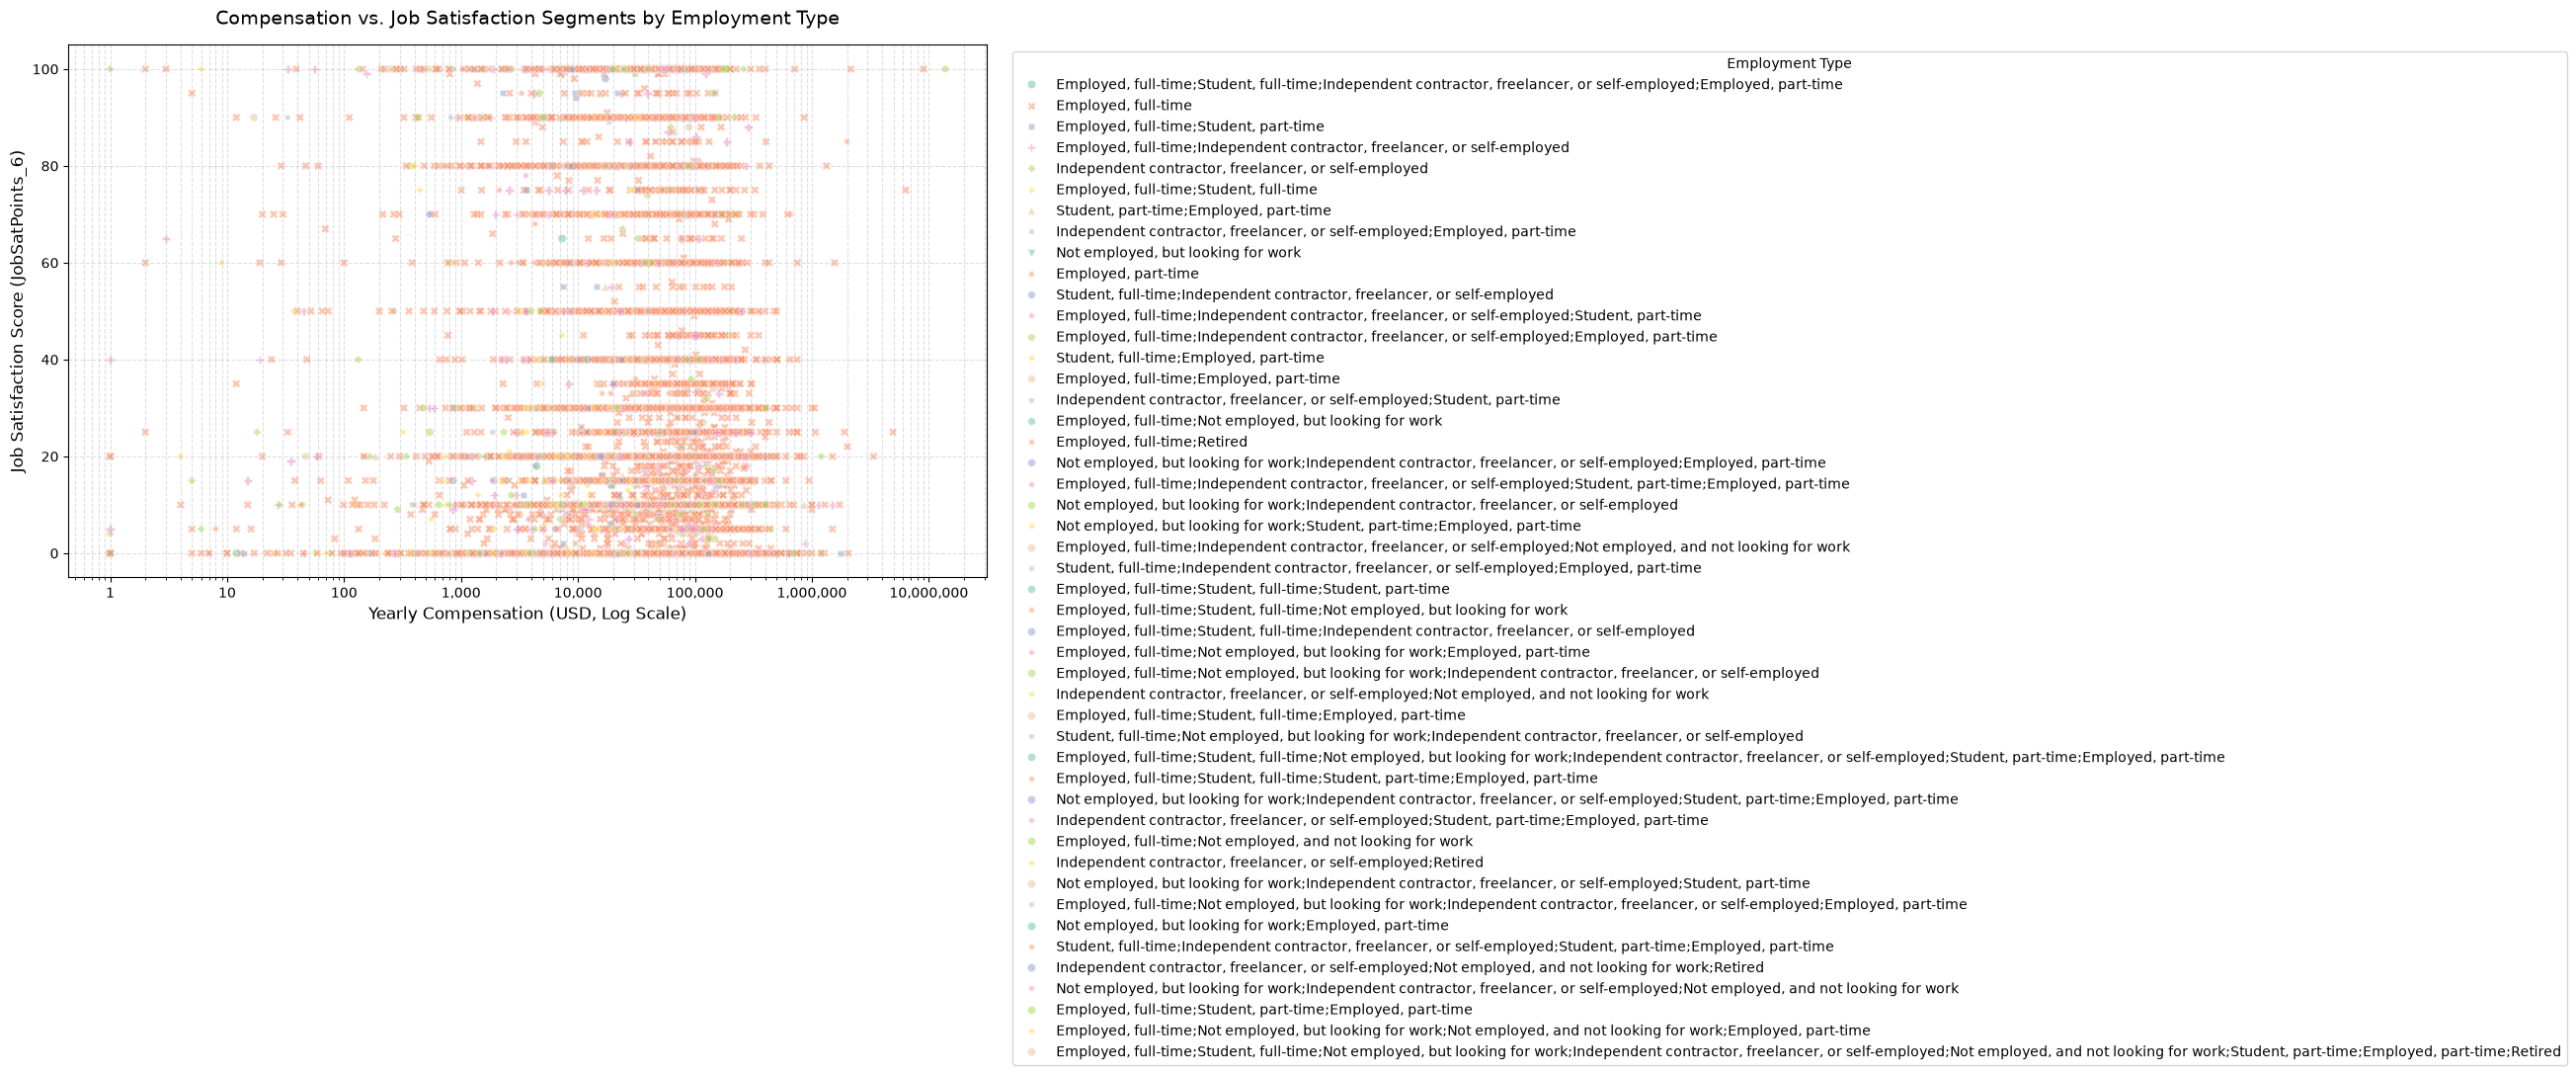

In [11]:
# Enforce uniform numeric types for target variables
df['ConvertedCompYearly'] = pd.to_numeric(df['ConvertedCompYearly'], errors='coerce')
df['JobSatPoints_6'] = pd.to_numeric(df['JobSatPoints_6'], errors='coerce')

# Drop rows missing critical metrics or categorical variables
df_emp = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6', 'Employment'])

plt.figure(figsize=(12, 7))

# Generate the scatter plot using seaborn for automated categorization splits
sns.scatterplot(
    data=df_emp, 
    x='ConvertedCompYearly', 
    y='JobSatPoints_6', 
    hue='Employment', 
    style='Employment',  # Differentiates employment categories with unique shapes
    alpha=0.5,           # Semi-transparency helps resolve overlapping points
    palette='Set2'       # High-contrast, clean color palette
)

# Apply a log scale to prevent extreme outliers from compressing the bulk distribution
plt.xscale('log')

# Format the x-axis numbers to show standard commas instead of scientific notation
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# Titles, legend positioning, and axis labels
plt.title('Compensation vs. Job Satisfaction Segments by Employment Type', fontsize=14, pad=15)
plt.xlabel('Yearly Compensation (USD, Log Scale)', fontsize=12)
plt.ylabel('Job Satisfaction Score (JobSatPoints_6)', fontsize=12)

# Push the legend outside of the main chart bounding box so it doesn't overlap text
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Employment Type')

plt.grid(True, which="both", linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


#### 2. Scatter Plot for Work Experience vs. Age Group by Country


Compare work experience (`YearsCodePro`) across different age groups (`Age`) and countries (`Country`). Use colors to represent different countries and markers for age groups.


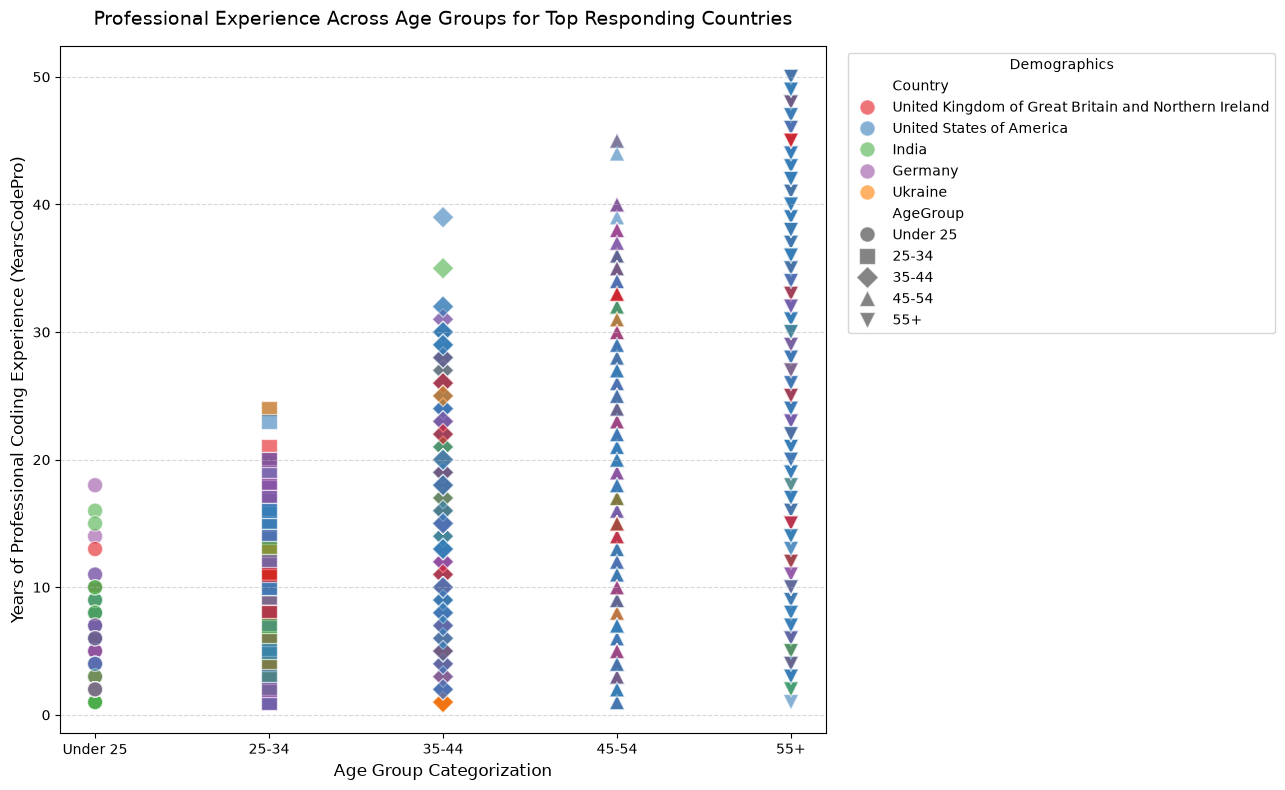

In [12]:
# Enforce clean numeric data structures
df['Age'] = pd.to_numeric(df['Age'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce')

# Drop missing values across our target metrics
df_clean = df.dropna(subset=['Age', 'YearsCodePro', 'Country']).copy()

# Categorize individual ages into clear, structured Age Groups
age_bins = [0, 24, 34, 44, 54, 100]
age_labels = ['Under 25', '25-34', '35-44', '45-54', '55+']
df_clean['AgeGroup'] = pd.cut(df_clean['Age'], bins=age_bins, labels=age_labels)

# Filter for the Top 5 most represented countries to prevent visual clutter
top_countries = df_clean['Country'].value_counts().nlargest(5).index
df_filtered = df_clean[df_clean['Country'].isin(top_countries)]

plt.figure(figsize=(13, 8))

# Generate the multi-dimensional scatter plot
sns.scatterplot(
    data=df_filtered,
    x='AgeGroup',
    y='YearsCodePro',
    hue='Country',
    style='AgeGroup',
    markers=['o', 's', 'D', '^', 'v'], # Assigns distinct shapes to each age group track
    s=120,                             # Distinct dot size for screen scannability
    alpha=0.6,                         # Translucency resolves packed markers
    palette='Set1'                     # Bold color separation for countries
)

# Text, titles, and layout formatting
plt.title('Professional Experience Across Age Groups for Top Responding Countries', fontsize=14, pad=15)
plt.xlabel('Age Group Categorization', fontsize=12)
plt.ylabel('Years of Professional Coding Experience (YearsCodePro)', fontsize=12)

# Push the legend box outside the chart limits so it doesn't obstruct any markers
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Demographics')

plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Final Step: Review


With these scatter plots, you will have analyzed data relationships across multiple dimensions, including compensation, job satisfaction, employment types, and demographics, to uncover meaningful trends in the developer community.


### Summary


After completing this lab, you will be able to:
- Analyze how numerical variables relate across specific groups, such as employment types and countries.
- Use scatter plots effectively to represent multiple variables with color, size, and markers.
- Gain insights into compensation, satisfaction, and demographic trends using advanced scatter plot techniques.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
